# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, StackingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

SEED = 42

# Reading The File & Inspecting The Data

In [2]:
df = pd.read_csv("olist_delivery_model_dataset.csv")

In [3]:
print(df.shape)

(96470, 35)


In [29]:
df.columns

Index(['order_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'n_items', 'n_unique_products', 'n_sellers',
       'total_price', 'total_freight', 'total_weight_g', 'max_item_weight_g',
       'total_volume_cm3', 'avg_photos_qty', 'avg_description_length',
       'freight_ratio', 'main_product_category', 'seller_state', 'seller_city',
       'seller_zip_code_prefix', 'total_payment_value', 'max_installments',
       'n_payment_methods', 'main_payment_type', 'purchase_year',
       'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'is_weekend',
       'approval_lag_hours', 'seller_deadline_days', 'estimated_delivery_days',
       'same_state', 'same_city', 'state_route', 'delivery_days'],
      dtype='str')

In [4]:
df.head()

,order_id,customer_zip_code_prefix,customer_city,customer_state,n_items,n_unique_products,n_sellers,total_price,total_freight,total_weight_g,...,purchase_dayofweek,purchase_hour,is_weekend,approval_lag_hours,seller_deadline_days,estimated_delivery_days,same_state,same_city,state_route,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,3149,sao paulo,SP,1,1,1,29.99,8.72,500.0,...,0,10,0,0.178333,4.007431,15.544063,1,0,SP->SP,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,47813,barreiras,BA,1,1,1,118.70,22.76,400.0,...,1,20,0,30.713889,5.279745,19.137766,0,0,SP->BA,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,75265,vianopolis,GO,1,1,1,159.90,19.22,420.0,...,2,8,0,0.276111,5.011505,26.639711,0,0,SP->GO,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,59296,sao goncalo do amarante,RN,1,1,1,45.00,27.20,450.0,...,5,19,1,0.298056,5.012419,26.188819,0,0,MG->RN,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,9195,santo andre,SP,1,1,1,19.90,8.72,250.0,...,1,21,0,1.030556,5.967338,12.112049,1,0,SP->SP,2.873877


In [5]:
df.columns

Index(['order_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'n_items', 'n_unique_products', 'n_sellers',
       'total_price', 'total_freight', 'total_weight_g', 'max_item_weight_g',
       'total_volume_cm3', 'avg_photos_qty', 'avg_description_length',
       'freight_ratio', 'main_product_category', 'seller_state', 'seller_city',
       'seller_zip_code_prefix', 'total_payment_value', 'max_installments',
       'n_payment_methods', 'main_payment_type', 'purchase_year',
       'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'is_weekend',
       'approval_lag_hours', 'seller_deadline_days', 'estimated_delivery_days',
       'same_state', 'same_city', 'state_route', 'delivery_days'],
      dtype='str')

In [25]:
df.estimated_delivery_days.describe()

count    96470.000000
mean        23.736343
std          8.761052
min          2.008009
25%         18.329905
50%         23.230880
75%         28.407795
max        155.135463
Name: estimated_delivery_days, dtype: float64

In [6]:
df.delivery_days.describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

# Feature Selection, Split, and Preprocessing Pipeline

In [7]:
cat_cols = ["customer_state", "seller_state", "main_product_category"]
num_cols = ['customer_zip_code_prefix','n_items', 'n_unique_products', 'n_sellers',
       'total_price', 'total_freight', 'total_weight_g', 'max_item_weight_g',
       'total_volume_cm3', 'avg_photos_qty', 'avg_description_length',
       'freight_ratio','seller_zip_code_prefix', 'purchase_month', 
       'purchase_dayofweek', 'purchase_hour', 'is_weekend',
       'same_state', 'same_city']

X = df[num_cols + cat_cols]
y = df["delivery_days"]

In [8]:
x_train_val, x_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.2, random_state=SEED)

In [9]:
X_y_train = x_train.copy()
X_y_train['label'] = y_train
X_y_train

,customer_zip_code_prefix,n_items,n_unique_products,n_sellers,total_price,total_freight,total_weight_g,max_item_weight_g,total_volume_cm3,avg_photos_qty,...,purchase_month,purchase_dayofweek,purchase_hour,is_weekend,same_state,same_city,customer_state,seller_state,main_product_category,label
54600,71503,1,1,1,79.90,18.44,500.0,500.0,2816.0,5.0,...,3,0,23,0,0,0,DF,SP,auto,14.854097
4122,85585,1,1,1,322.00,186.38,20650.0,20650.0,158760.0,3.0,...,3,2,22,0,0,0,PR,SC,auto,47.897836
64768,27288,1,1,1,127.90,18.78,350.0,350.0,4693.0,1.0,...,3,0,22,0,0,0,RJ,SP,computers_accessories,29.919583
3734,14177,1,1,1,57.99,11.91,200.0,200.0,5712.0,2.0,...,2,1,12,0,1,0,SP,SP,pet_shop,14.281875
3210,6114,1,1,1,134.90,16.05,8750.0,8750.0,18000.0,2.0,...,4,5,17,1,1,0,SP,SP,pet_shop,4.686725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4399,5009,1,1,1,12.90,7.78,150.0,150.0,4913.0,1.0,...,6,1,11,0,1,0,SP,SP,health_beauty,1.936273
39103,75388,1,1,1,28.80,16.39,700.0,700.0,9600.0,1.0,...,8,3,17,0,0,0,GO,SP,housewares,14.035729
18711,25515,1,1,1,119.90,18.09,1500.0,1500.0,7616.0,1.0,...,9,6,20,1,0,0,RJ,SP,bed_bath_table,11.015289
9292,29060,1,1,1,29.99,14.10,343.0,343.0,8512.0,2.0,...,1,5,10,1,0,0,ES,SP,electronics,10.530903


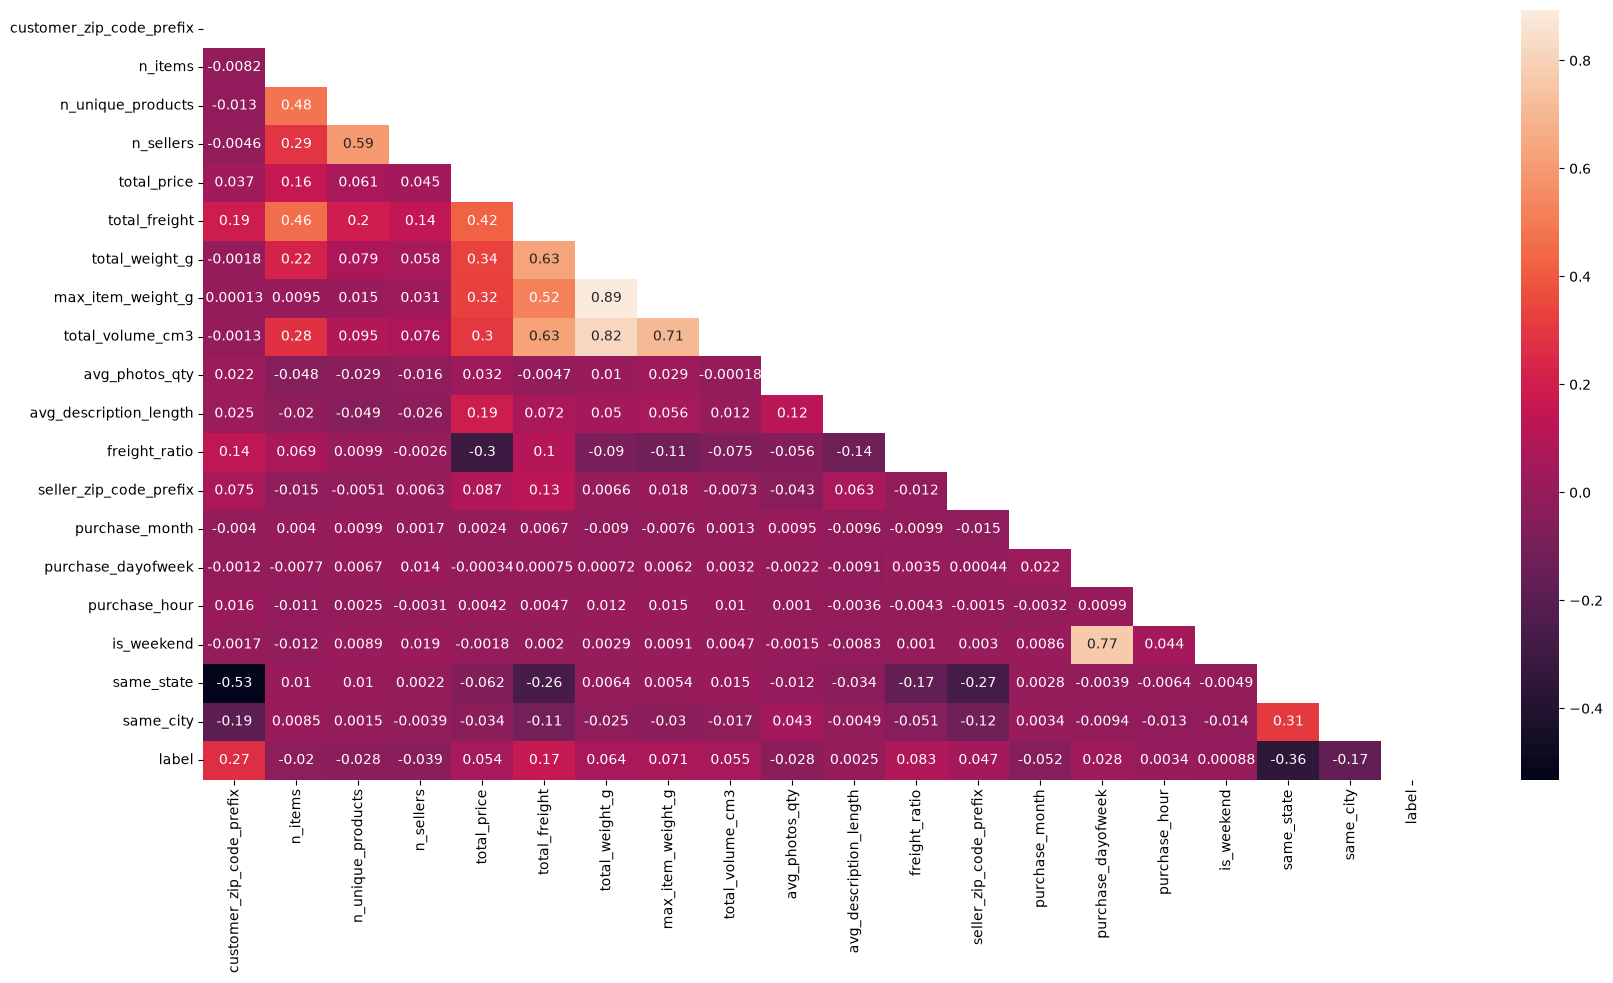

In [10]:
corr_matrix = X_y_train.corr(numeric_only=True)
lower_no_diag = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))
plt.figure(figsize=(20, 10))
sns.heatmap(lower_no_diag, annot=True);

In [11]:
def make_preprocessor(scale):
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:                                   
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))]), cat_cols)])

def evaluate(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": root_mean_squared_error(y_true, pred),
            "R2": r2_score(y_true, pred)}


# Linear Regression

In [12]:
lr_pipe = Pipeline([("prep", make_preprocessor(scale=True)), ("model", LinearRegression())])
lr_pipe.fit(x_train, y_train)

y_pred_lr = lr_pipe.predict(x_val)
results_lr = evaluate(y_val, y_pred_lr)
print(results_lr)


{'MAE': 5.32140587293604, 'RMSE': 8.507335142169689, 'R2': 0.2271997887143664}


# Decision Tree

In [11]:
dt_pipe = Pipeline([("prep", make_preprocessor(scale=False)), 
    ("model", DecisionTreeRegressor())])
dt_pipe.fit(x_train, y_train)

y_pred_dt = dt_pipe.predict(x_val)
results_dt = evaluate(y_val, y_pred_dt)
print(results_dt)

{'MAE': 6.669239503378545, 'RMSE': 11.450792464676592, 'R2': -0.4000747888170999}


In [13]:
param_grid_dt = {"model__max_depth": [6, 8, 12], 
    "model__min_samples_leaf": [20, 50]}

dt_search = GridSearchCV(dt_pipe, param_grid=param_grid_dt)
dt_search.fit(x_train, y_train)
print("best settings:", dt_search.best_params_)


best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 50}


In [13]:
dt_pipe_final = Pipeline([("prep", make_preprocessor(scale=False)),
    ("model", DecisionTreeRegressor(max_depth=8, min_samples_leaf=20))])
dt_pipe_final.fit(x_train, y_train)
y_pred_dt_final = dt_pipe_final.predict(x_val)
results_dt_final = evaluate(y_val, y_pred_dt_final)
print(results_dt_final)

{'MAE': 5.032362170826376, 'RMSE': 8.200053908495729, 'R2': 0.28201798880901763}


# Random Forest

In [14]:
rf = Pipeline([("prep", make_preprocessor(scale=False)),
               ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=10, max_features=0.3,
                                               n_jobs=-1, random_state=SEED))])
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_val)
results_rf = evaluate(y_val, y_pred_rf)
print(results_rf)

{'MAE': 4.79039173146343, 'RMSE': 7.952431383835489, 'R2': 0.3247260296813457}


# Gradient Boosting

In [14]:
hgb_pipe = Pipeline([("prep", make_preprocessor(scale=False)),
              ("model", HistGradientBoostingRegressor())])
hgb_pipe.fit(x_train, y_train)
y_pred_hgb = hgb_pipe.predict(x_val)
results_hgb = evaluate(y_val, y_pred_hgb)
print(results_hgb)

{'MAE': 4.799626531178058, 'RMSE': 7.927950550012135, 'R2': 0.32887716888735763}


In [17]:
param_grid={"model__learning_rate": [0.1], "model__max_leaf_nodes": [31, 63], "model__max_iter": [200]}

hgb_search = GridSearchCV(hgb_pipe, param_grid=param_grid)
hgb_search.fit(x_train, y_train)
print("best settings:", hgb_search.best_params_)

best settings: {'model__learning_rate': 0.1, 'model__max_iter': 200, 'model__max_leaf_nodes': 31}


In [15]:
hgb_pipe_final = Pipeline([("prep", make_preprocessor(scale=False)),
    ("model", HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=63, max_iter=200))])
hgb_pipe_final.fit(x_train, y_train)
y_pred_hgb_final = hgb_pipe_final.predict(x_val)
results_hgb_final = evaluate(y_val, y_pred_hgb_final)
print(results_hgb_final)

{'MAE': 4.756396633169426, 'RMSE': 7.886460527574028, 'R2': 0.3358832771099687}


In [16]:
y_pred_hgb_finaltest = hgb_pipe_final.predict(x_test)
results_hgb_finaltest = evaluate(y_test, y_pred_hgb_finaltest)
print(results_hgb_finaltest)

{'MAE': 4.686174565468226, 'RMSE': 7.497922787036463, 'R2': 0.3518822268805698}


# Stacking

In [17]:
estimators = [('dt', DecisionTreeRegressor(max_depth=8, min_samples_leaf=20)),
    ('rf', RandomForestRegressor(n_estimators=100, min_samples_leaf=10, max_features=0.3, n_jobs=-1, random_state=SEED)),
    ('hgb', HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=63, max_iter=200))]
final_model = HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=63, max_iter=200)

stk_pipe = Pipeline([("prep", make_preprocessor(scale=False)), ("model", StackingRegressor(estimators=estimators, final_estimator=final_model))])
stk_pipe.fit(x_train, y_train)
y_pred_stk = stk_pipe.predict(x_val)
results_stk = evaluate(y_val, y_pred_stk)
print(results_stk)

{'MAE': 4.761618201850532, 'RMSE': 7.905360611088448, 'R2': 0.3326963209605006}


In [18]:
y_pred_stktest = stk_pipe.predict(x_test)
results_stktest = evaluate(y_test, y_pred_stktest)
print(results_stktest)

{'MAE': 4.699321503305688, 'RMSE': 7.542793556426975, 'R2': 0.3441017889790997}


# Model Comparison

In [17]:
all_results = {
    "Linear Regression": results_lr,
    "Decision Tree": results_dt_final,
    "Random Forest": results_rf,
    "HistGradient Boosting": results_hgb_final}

df_results = pd.DataFrame.from_dict(all_results, orient='index').round(2)
df_results

,MAE,RMSE,R2
Linear Regression,5.32,8.51,0.23
Decision Tree,5.03,8.20,0.28
Random Forest,4.79,7.95,0.32
HistGradient Boosting,4.76,7.89,0.34


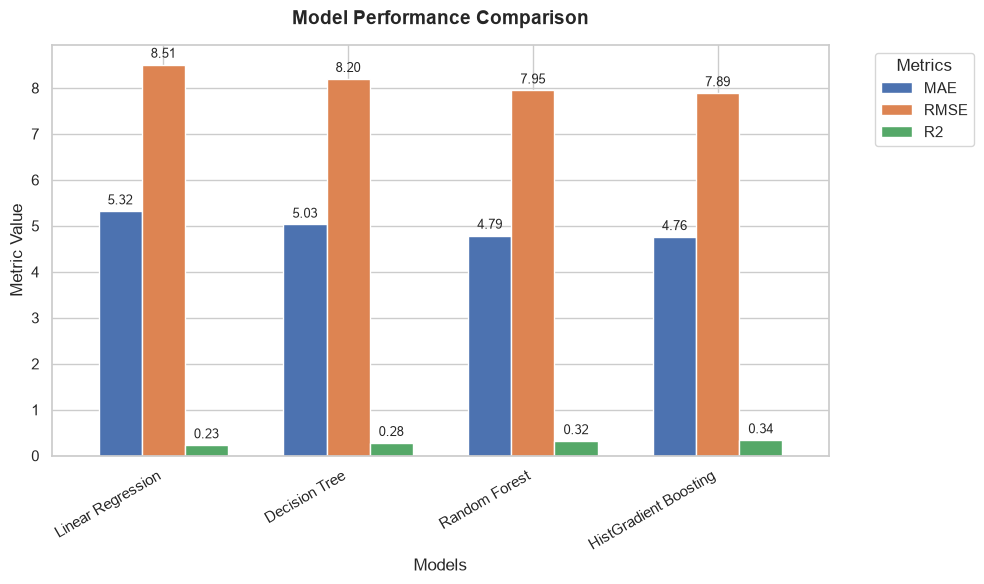

In [18]:
# Set the plot style and figure size
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the metrics (assumes your variables contain columns like MAE, RMSE, etc.)
df_results.plot(kind="bar", ax=ax, width=0.7)

# Formatting the chart
ax.set_title("Model Performance Comparison", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Metric Value", fontsize=12)
ax.set_xlabel("Models", fontsize=12)
ax.set_xticklabels(df_results.index, rotation=30, ha="right")
ax.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc='upper left')

# Add values on top of the bars for easy scanning
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)

plt.tight_layout()
plt.show()


# Feature Importance

In [19]:
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = rf.named_steps["model"].feature_importances_

imp_df = pd.DataFrame({
    'col_name': feature_names,
    'feature_importance': importances})
imp_df = imp_df.sort_values(by='feature_importance', ascending=False)
imp_df

,col_name,feature_importance
0,num__customer_zip_code_prefix,0.157013
13,num__purchase_month,0.139889
17,num__same_state,0.128885
5,num__total_freight,0.089641
44,cat__customer_state_SP,0.067211
...,...,...
98,cat__main_product_category_fashion_male_clothing,0.000000
100,cat__main_product_category_fashion_sport,0.000000
101,cat__main_product_category_fashion_underwear_b...,0.000000
103,cat__main_product_category_flowers,0.000000


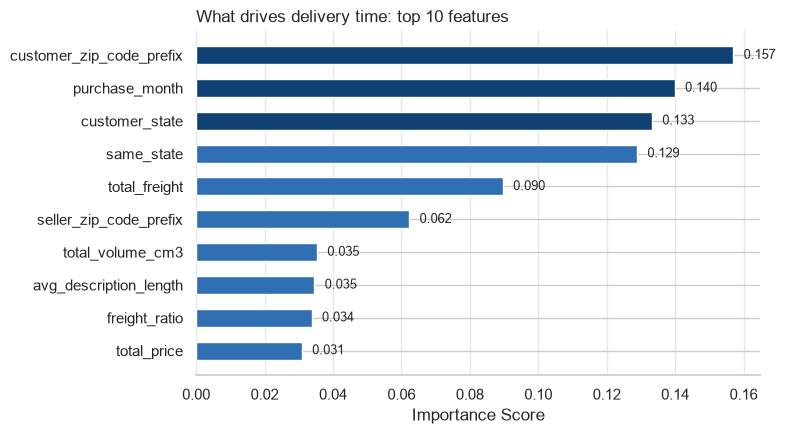

In [20]:
prep_fitted = rf.named_steps["prep"]
importances = pd.Series(rf.named_steps["model"].feature_importances_,
                        index=prep_fitted.get_feature_names_out())

def original_name(name):                 # group one-hot columns back to their original feature
    name = name.split("__", 1)[1]
    for c in cat_cols:
        if name.startswith(c + "_"):
            return c
    return name

grouped = importances.groupby(original_name).sum().sort_values(ascending=False)
top = grouped.head(10)[::-1]

# Create a color list: dark blue for the last 3 items (top 3 features), lighter blue for the rest
colors = ["#2f6fb2" if i < len(top) - 3 else "#104175" for i in range(len(top))]
fig, ax = plt.subplots(figsize=(8, 4.5))

# Pass the colors list here
ax.barh(top.index, top.values, color=colors, height=0.55)
for i, v in enumerate(top.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Importance Score")
ax.set_title("What drives delivery time: top 10 features", loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.grid(True, color="#e4e7eb")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


# Error Analysis

In [21]:
residuals = y_val - y_pred_hgb_final
residuals

91186     1.034767
60273     0.145412
694      -4.349898
55646    -3.882042
29715     0.678990
           ...    
25931    -0.341331
58802    -3.006306
66053     8.880583
90235    10.459365
88659    -7.711441
Name: delivery_days, Length: 15436, dtype: float64

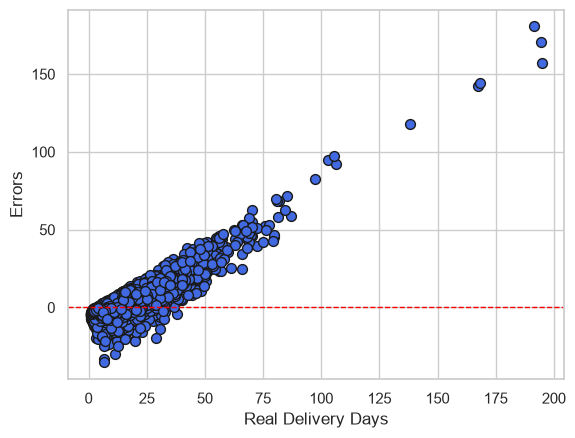

In [22]:
plt.scatter(y_val, residuals, color='royalblue', edgecolor='k', s=50)
plt.xlabel("Real Delivery Days")
plt.ylabel("Errors")
plt.axhline(0, color='red', linestyle='--', linewidth=1)

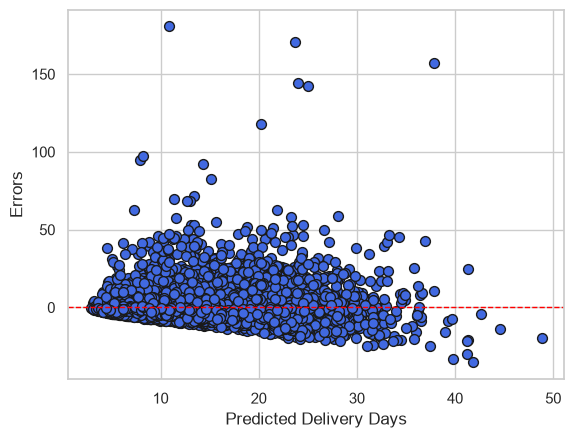

In [23]:
plt.scatter(y_pred_hgb_final, residuals, color='royalblue', edgecolor='k', s=50)
plt.xlabel("Predicted Delivery Days")
plt.ylabel("Errors")
plt.axhline(0, color='red', linestyle='--', linewidth=1)

In [24]:
print("Mean residual:", residuals.mean())
print("Median residual:", residuals.median())

Mean residual: 0.09307190678561929
Median residual: -1.2840734743051139


In [27]:
val_df = x_val.copy()
val_df['y_true'] = y_val
val_df['y_pred'] = y_pred_hgb_final
val_df['abs_error'] = np.abs(residuals)
val_df

,customer_zip_code_prefix,n_items,n_unique_products,n_sellers,total_price,total_freight,total_weight_g,max_item_weight_g,total_volume_cm3,avg_photos_qty,...,purchase_hour,is_weekend,same_state,same_city,customer_state,seller_state,main_product_category,y_true,y_pred,abs_error
91186,92440,1,1,1,58.99,17.25,800.0,800.0,18750.0,4.0,...,13,0,0,0,RS,SP,sports_leisure,19.591887,20.504083,0.912197
60273,19470,1,1,1,49.99,13.37,1600.0,1600.0,17500.0,1.0,...,8,0,1,0,SP,SP,health_beauty,6.455718,6.391543,0.064174
694,24350,1,1,1,21.90,14.10,200.0,200.0,2912.0,1.0,...,21,0,0,0,RJ,SP,electronics,16.023889,18.725828,2.701939
55646,35600,1,1,1,9.60,16.11,500.0,500.0,4608.0,1.0,...,20,0,0,0,MG,SP,housewares,6.735162,10.739514,4.004352
29715,18050,1,1,1,114.08,13.46,400.0,400.0,5632.0,2.0,...,23,0,1,0,SP,SP,perfumery,9.726586,8.515500,1.211085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25931,5422,2,1,1,36.48,14.78,400.0,200.0,3520.0,1.0,...,12,0,1,1,SP,SP,garden_tools,4.138565,4.389364,0.250799
58802,14887,1,1,1,75.25,12.97,200.0,200.0,4000.0,2.0,...,20,0,1,0,SP,SP,health_beauty,5.992801,8.845613,2.852812
66053,29190,2,2,2,264.80,47.00,4600.0,2300.0,33486.0,2.0,...,11,1,0,0,ES,SP,baby,20.203484,10.680652,9.522832
90235,38410,1,1,1,120.00,23.42,1550.0,1550.0,5184.0,5.0,...,14,1,0,0,MG,SP,stationery,24.388403,14.372166,10.016237


# For Deployment

In [ ]:
import joblib
joblib.dump(full_pipe, "model.pkl")